## Clasificacion Titanic

Para este ejemplo vamos a utilizar el dataset Titanic, un caso clásico de aprendizaje supervisado. El objetivo es construir un modelo que prediga si un pasajero sobrevivió o no al hundimiento del Titanic a partir de sus características.
Es una práctica especialmente útil porque combina variables numéricas y categóricas, valores faltantes y una variable objetivo binaria.

### El modelo utilizará variables como:
Variable	Descripción
Pclass	Clase del pasaje: 1, 2 o 3
Sex	Sexo registrado del pasajero
Age	Edad
SibSp	Hermanos, hermanas o cónyuge a bordo
Parch	Padres, madres o hijos a bordo
Fare	Tarifa pagada
Embarked	Puerto de embarque

### La variable objetivo será Survived:
- 0: no sobrevivió.
- 1: sobrevivió.

Cantidad de registros: 891

Valores faltantes:
pclass        0
sex           0
age         177
sibsp         0
parch         0
fare          0
embarked      2
dtype: int64

Distribución de supervivencia:
survived
0    549
1    342
Name: count, dtype: int64

Accuracy: 0.8045

Reporte de clasificación:
               precision    recall  f1-score   support

No sobrevivió       0.81      0.89      0.85       110
   Sobrevivió       0.79      0.67      0.72        69

     accuracy                           0.80       179
    macro avg       0.80      0.78      0.79       179
 weighted avg       0.80      0.80      0.80       179



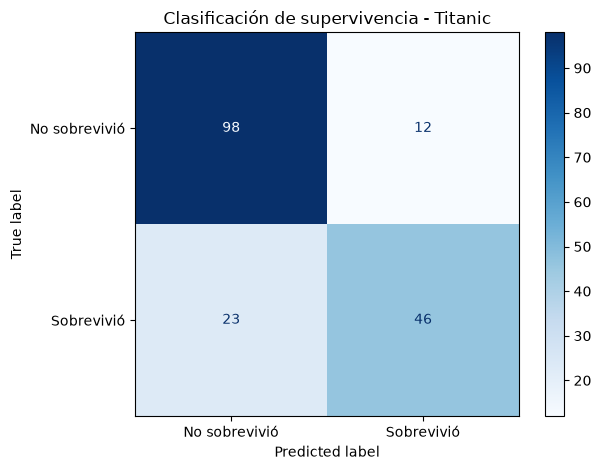


Predicción para el nuevo pasajero:
Resultado: Sobrevivió
Probabilidad estimada de supervivencia: 93.04%


: 

In [ ]:

import seaborn as sns
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    ConfusionMatrixDisplay
)

# 1. Cargar el dataset
df = sns.load_dataset("titanic")

# 2. Seleccionar variables predictoras y objetivo
columnas = [
    "pclass", "sex", "age", "sibsp",
    "parch", "fare", "embarked"
]

X = df[columnas]
y = df["survived"]

print("Cantidad de registros:", len(df))
print("\nValores faltantes:")
print(X.isnull().sum())

print("\nDistribución de supervivencia:")
print(y.value_counts())

# 3. Separar variables numéricas y categóricas
numericas = ["pclass", "age", "sibsp", "parch", "fare"]
categoricas = ["sex", "embarked"]

# 4. Preparar el procesamiento de datos
procesamiento_numerico = Pipeline([
    ("imputacion", SimpleImputer(strategy="median")),
    ("escalado", StandardScaler())
])

procesamiento_categorico = Pipeline([
    ("imputacion", SimpleImputer(strategy="most_frequent")),
    ("codificacion", OneHotEncoder(handle_unknown="ignore"))
])

preprocesador = ColumnTransformer([
    ("numericas", procesamiento_numerico, numericas),
    ("categoricas", procesamiento_categorico, categoricas)
])

# 5. Crear el modelo completo
modelo = Pipeline([
    ("preprocesamiento", preprocesador),
    ("clasificador", LogisticRegression(max_iter=1000))
])

# 6. Dividir datos en entrenamiento y prueba
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

# 7. Entrenar el modelo
modelo.fit(X_train, y_train)

# 8. Predecir la supervivencia
y_pred = modelo.predict(X_test)

# 9. Evaluar el modelo
print("\nAccuracy:", round(accuracy_score(y_test, y_pred), 4))

print("\nReporte de clasificación:")
print(classification_report(
    y_test,
    y_pred,
    target_names=["No sobrevivió", "Sobrevivió"],
    zero_division=0
))

# 10. Visualizar matriz de confusión
ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred,
    labels=[0, 1],
    display_labels=["No sobrevivió", "Sobrevivió"],
    cmap="Blues"
)

plt.title("Clasificación de supervivencia - Titanic")
plt.tight_layout()
plt.show()

# 11. Predecir un pasajero nuevo
nuevo_pasajero = pd.DataFrame([{
    "pclass": 1,
    "sex": "female",
    "age": 30,
    "sibsp": 0,
    "parch": 0,
    "fare": 80.0,
    "embarked": "S"
}])

prediccion = modelo.predict(nuevo_pasajero)[0]
probabilidad = modelo.predict_proba(nuevo_pasajero)[0, 1]

print("\nPredicción para el nuevo pasajero:")
print("Resultado:", "Sobrevivió" if prediccion == 1
      else "No sobrevivió")
print(f"Probabilidad estimada de supervivencia: {probabilidad:.2%}")
